In [318]:
from pathlib import Path

import numpy as np
import scipy 
import pandas as pd
from scipy.linalg import svdvals
from scipy.io import loadmat
from scipy.optimize import curve_fit
from matplotlib.ticker import MaxNLocator


import matplotlib.pyplot as plt

%matplotlib inline 

In [Integrating time from experience in the lateral entorhinal cortex](https://www.nature.com/articles/s41586-018-0459-6#ref-CR31), the strongest evidence of ramping activity comes from lateral entorhinal cortex. The experiment performed was hours long with a rat running in a box in which the colour of the walls alternated between black and white in a fixed pattern over 12 trials. (BW12 experiment, data: data21941_lec_bw12.mat, data21788_lec_bw12.mat), the spike time unit is in seconds.

In [319]:
bw12_21941_path = Path("lec_time1/data21941_lec_bw12.mat")
bw12_21788_path = Path("lec_time1/data21788_lec_bw12.mat")
bw12_21941_file = loadmat(bw12_21941_path)
bw12_21788_file = loadmat(bw12_21788_path)
cells_21941_data = bw12_21941_file['cells']
cells_21788_data = bw12_21788_file['cells']


print(bw12_21941_file.keys())
print(bw12_21788_file.keys())
print(f"Number of neurons for experiment 21941: {bw12_21941_file['cells'].shape[1]}")
print(f"Number of neurons for experiment 21788: {bw12_21788_file['cells'].shape[1]}")

dict_keys(['__header__', '__version__', '__globals__', 'cells', 'position'])
dict_keys(['__header__', '__version__', '__globals__', 'cells', 'position'])
Number of neurons for experiment 21941: 220
Number of neurons for experiment 21788: 90


In [320]:
max_time_length_21941 = []
for i in range(cells_21941_data.shape[1]):
    max_time_length_21941.append(cells_21941_data[0,i].max())
    
max_time_length_21788 = []
for i in range(cells_21788_data.shape[1]):
    max_time_length_21788.append(cells_21788_data[0,i].max())

print(f'maximum recorded length for experiment 21941 (s): \
{np.round(np.max(max_time_length_21941), 2)} s')
print(f'maximum recorded length for experiment 21788 (s): \
{np.round(np.max(max_time_length_21788), 2)} s')

maximum recorded length for experiment 21941 (s): 4680.0 s
maximum recorded length for experiment 21788 (s): 4679.99 s


From [Integrating time from experience in the lateral entorhinal cortex](https://www.nature.com/articles/s41586-018-0459-6#ref-CR31), the animal ran 12 250 s trials and 140 s intertrial periods in which the animal was placed in a holding pot. Compute th firing rate of a neuron by using the PSTH. The firing rate of neuron $i$ for time bin $j$ is as follows, 
$$r_i(t_j) = \frac{\text{number of spikes in bin j}}{\Delta t}$$

(235,)


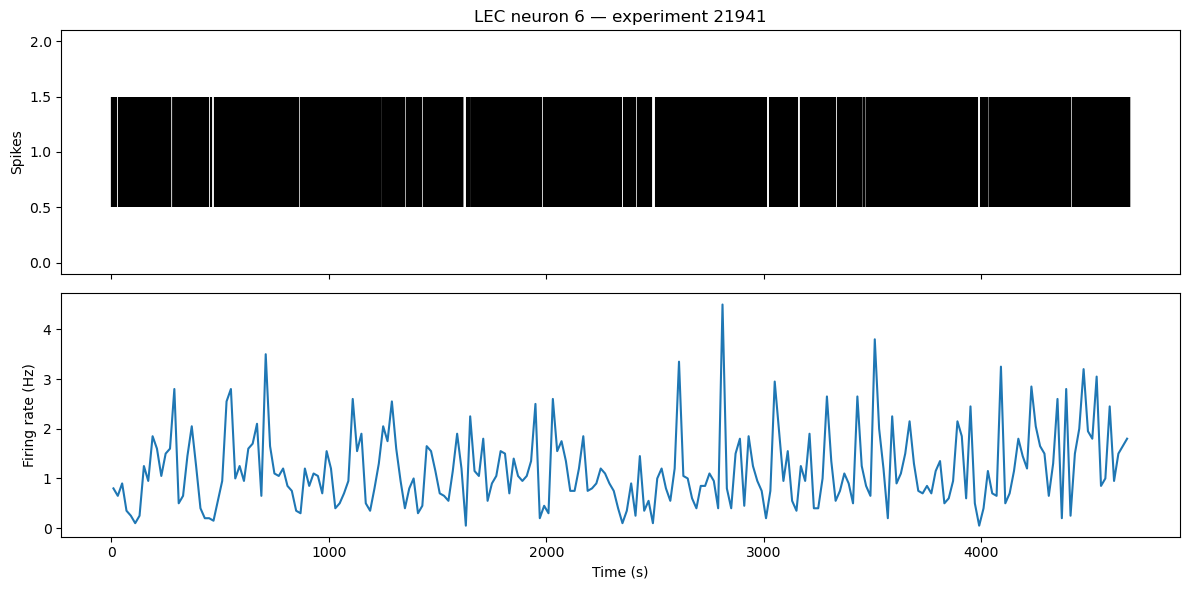

In [321]:
neuron_i = 6
spike_times = np.asarray(
    cells_21941_data[0, neuron_i]
).ravel()

# BW12 experiment
session_duration = 4680  # seconds
dt = 20           # time bins duration

time_edges = np.arange(0, session_duration + dt, dt)
time_centers = (time_edges[:-1] + time_edges[1:]) / 2

print(time_edges.shape)
# Number of spikes in each time bin
counts, _ = np.histogram(spike_times, bins=time_edges)

# Convert to firing rate (Hz)
firing_rate = counts / dt

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Spike raster
axes[0].eventplot(spike_times, colors="black")
axes[0].set_ylabel("Spikes")
axes[0].set_title(f"LEC neuron {neuron_i} — experiment 21941")

# Firing rate
axes[1].plot(time_centers, firing_rate)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Firing rate (Hz)")

plt.tight_layout()
plt.show()

The trial averaged population firing rate matrix is as follows,
$$R_{ij} = \frac{1}{12} \sum^{12}_{r = 1} \frac{N_{irj}}{\Delta t}$$
where $N_{irj}$ is the spike count for neuron $i$, trial $r$ and time bin $j$.

In [345]:
n_trials = 12
trial_duration = 250
iti_duration = 140
cycle_duration = trial_duration + iti_duration

dt = 10

# we are computing PSTH from 0 to the end of a trial 250
trial_edges = np.arange(0, trial_duration + dt, dt)
trial_centers = (trial_edges[:-1] + trial_edges[1:]) / 2

# Number of neurons
n_neurons = cells_21941_data.size
n_bins = len(trial_centers)

# Neurons x Trials x Time bins
trial_rates = np.zeros((n_neurons, n_trials, n_bins))

for i, cell in enumerate(cells_21941_data.ravel()):
    spikes = np.asarray(cell).ravel()

    for r in range(n_trials):
        # Trial begins after the intertrial interval
        trial_start = iti_duration + r * cycle_duration
        trial_end = trial_start + trial_duration

        # Select spikes within this trial
        # we need to subtract trail_start because we need
        # to compute PTSH from trail_edges, which starts from 0
        trial_spikes = spikes[
            (spikes >= trial_start) &
            (spikes < trial_end)
        ] - trial_start

        counts, _ = np.histogram(trial_spikes, bins=trial_edges)

        # Firing rate in spikes per second
        trial_rates[i, r, :] = counts / dt

# Average across 12 trials, which is the column, axis 1
R = trial_rates.mean(axis=1)

print("Trial rates:", trial_rates.shape)
print("Population firing-rate matrix:", R.shape)

Trial rates: (220, 12, 25)
Population firing-rate matrix: (220, 25)


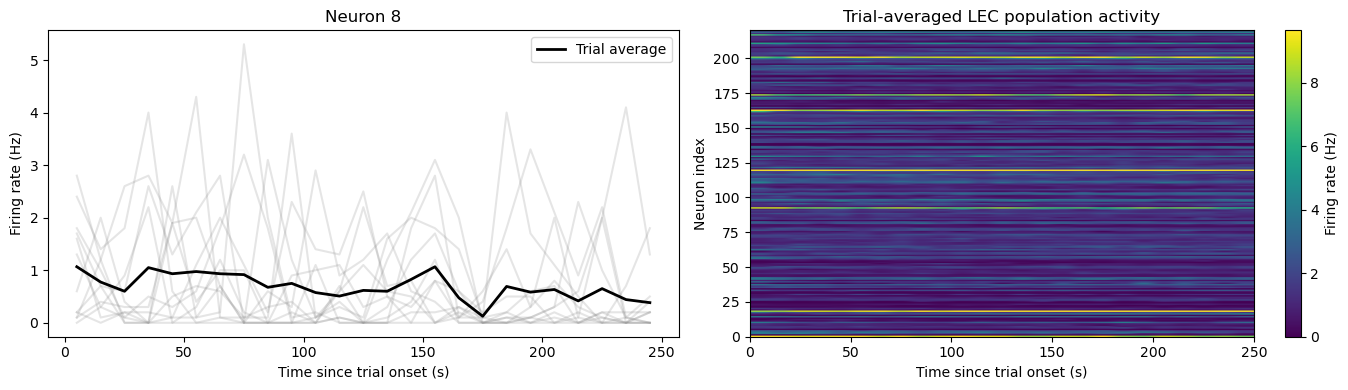

In [346]:
neuron_i = 8

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Individual trials
for r in range(n_trials):
    axes[0].plot(
        trial_centers,
        trial_rates[neuron_i, r,:],
        alpha=0.2,
        color="gray"
    )

# Average across trials
axes[0].plot(
    trial_centers,
    R[neuron_i],
    color="black",
    linewidth=2,
    label="Trial average"
)

axes[0].set_xlabel("Time since trial onset (s)")
axes[0].set_ylabel("Firing rate (Hz)")
axes[0].set_title(f"Neuron {neuron_i}")
axes[0].legend()

# Population heatmap
im = axes[1].imshow(
    R,
    aspect="auto",
    origin="lower",
    extent=[0, trial_duration, 0, n_neurons],
    vmin=0,
    vmax=np.percentile(R, 99)
)

axes[1].set_xlabel("Time since trial onset (s)")
axes[1].set_ylabel("Neuron index")
axes[1].set_title("Trial-averaged LEC population activity")
fig.colorbar(im, ax=axes[1], label="Firing rate (Hz)")

plt.tight_layout()
plt.show()

Looking at the Trial-averaged LEC population activity, we don't observe an exponential decay for every neuron in the population firing rate matrix. If we do, then we will likely see that pattern in the image. Therefore, we will fit an exponential decay model to every neuron's firing rates, and not other features in the experiment
$$r_i(t) = A_i e^{-\xi_i t} + b_i$$
where $A_i \geq 0$ is the amplitude, $\xi_i > 0$ is the decay rate and $b_i$ is the baseline firing rate. Then we will extract the neuron that reaches a certain $R^2$ threshold.

In [347]:
def exp_decay(t, A, xi, b):
    return A * np.exp(-xi * t) + b

results = []

for i, y in enumerate(R): # i is neuron i, y is firing rate, the data we are going to fit
    try: 
        popt, _ = curve_fit(
            exp_decay,
            trial_centers,
            y,
            p0 = [max(y[0] - y[-1], 0.01), 0.01, max(y[-1], 0)],
            bounds = (0, np.inf),
            maxfev = 10000
        )
        y_pred = exp_decay(trial_centers, *popt)

        ss_res = np.sum((y_pred - y)**2)
        ss_tot = np.sum((y - y.mean())**2)

        r2 = 1 - ss_res / ss_tot

        results.append([i, *popt, r2])
    except RuntimeError:
        results.append([i, np.nan, np.nan, np.nan, np.nan])

df = pd.DataFrame(
    results,
    columns=["neuron", "A", "xi", "baseline", "R2"]
)
df = df.sort_values("R2", ascending=False)
print(df.head(50))

     neuron            A        xi      baseline        R2
56       56     3.164670  0.067167  1.848365e+00  0.888666
182     182     2.557673  0.025353  1.090922e+00  0.800676
150     150     3.235469  0.028615  1.726279e+00  0.785766
2         2     3.194855  0.009596  8.403481e-01  0.767941
106     106     2.390129  0.085581  9.749580e-01  0.713470
156     156     1.334419  0.003005  3.419612e-17  0.709662
29       29     0.478594  0.035340  1.454520e-01  0.704315
113     113     1.817887  0.014308  1.300427e+00  0.684284
171     171     2.216228  0.020983  1.954173e+00  0.661811
216     216     4.943498  0.086904  3.649800e+00  0.658324
104     104     1.419854  0.048033  4.882220e-01  0.631553
4         4     2.530264  0.002679  1.294653e-17  0.624684
184     184     0.650342  0.063616  6.481234e-01  0.616730
17       17     2.881774  0.117946  1.641711e+00  0.602074
112     112     1.256611  0.006546  1.341696e+00  0.591767
0         0     9.882663  0.000854  4.116985e-13  0.5625

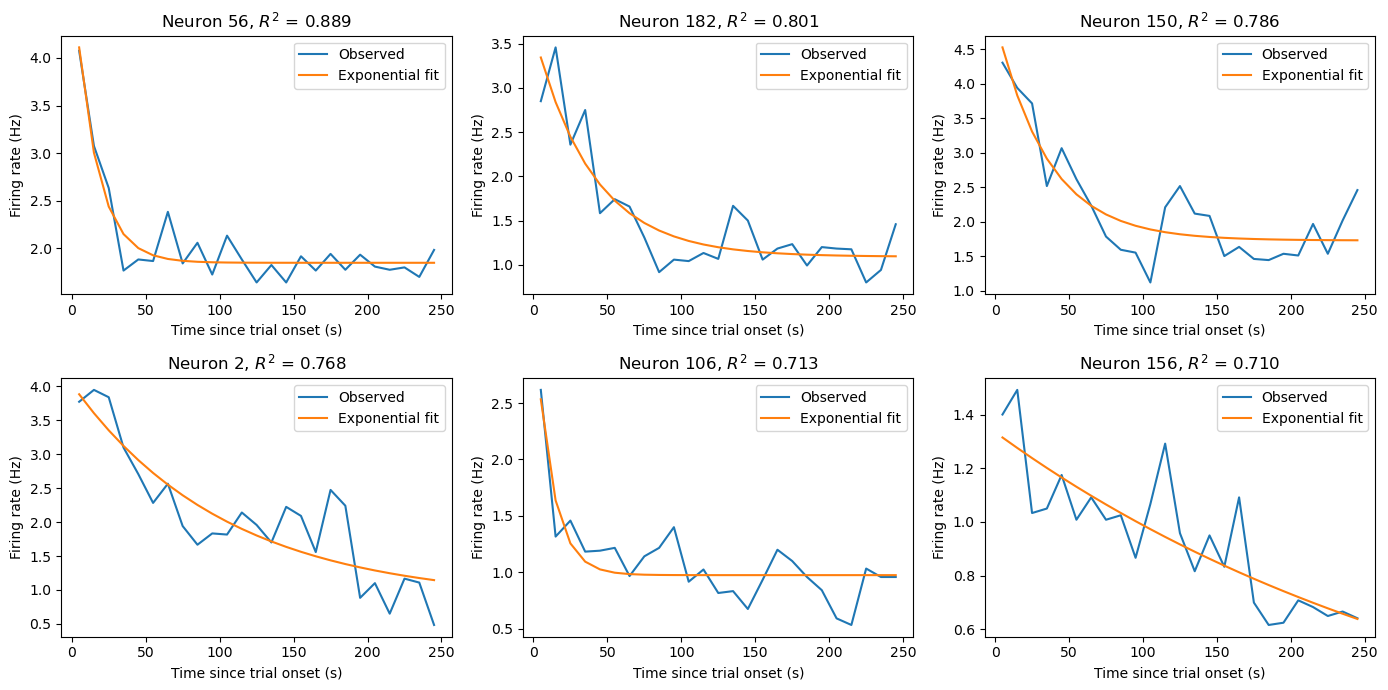

In [348]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, (_, row) in zip(axes.flat, df.head(6).iterrows()):
    i = int(row["neuron"])

    ax.plot(trial_centers, R[i], label="Observed")
    ax.plot(
        trial_centers,
        exp_decay(trial_centers, row["A"], row["xi"], row["baseline"]),
        label="Exponential fit"
    )

    ax.set_title(f"Neuron {i}, $R^2$ = {row['R2']:.3f}")
    ax.set_xlabel("Time since trial onset (s)")
    ax.set_ylabel("Firing rate (Hz)")
    ax.legend()

plt.tight_layout()
plt.show()

$\textbf{Note:}$ we use a threshold of 0.2 and choose 53 neurons, but this maybe subjected to change. Higher threshold of 0.3 and 0.4 are chosen and we see the result, the decay of singular values. 

In [349]:
threshold = 0.6

selected_neurons = df.loc[df["R2"] > threshold, "neuron"].to_numpy()

R_selected = R[selected_neurons]

# Fitted baseline for each selected neuron
baselines = (
    df.set_index("neuron")
      .loc[selected_neurons, "baseline"]
      .to_numpy()
)

R_baseline = R_selected - baselines[:, None]
R_centered = R_selected - R_selected.mean(axis=1, keepdims=True)

# Singular values
s_raw = svdvals(R_selected)
s_baseline = svdvals(R_baseline)
s_centered = svdvals(R_centered)

# Normalize by the largest singular value of each matrix
def normalize(s):
    return s / s[0] if s[0] > 0 else np.full_like(s, np.nan)

s_raw_norm = normalize(s_raw)
s_baseline_norm = normalize(s_baseline)
s_centered_norm = normalize(s_centered)

print(f"Selected {len(selected_neurons)} neurons")
print("R_selected shape:", R_selected.shape)

Selected 14 neurons
R_selected shape: (14, 25)


In [350]:
print(f'Rank of the firing matrix R is: {np.linalg.matrix_rank(R_selected)}')

Rank of the firing matrix R is: 14


$\textbf{Note}:$ we have three curves plotted below: the <span style="color: blue;">Raw firing rate</span> is the trial averaged population firing rate of the selected neuron R_selected; the <span style="color: orange;">Baseline subtracted </span> is the trial averaged population firing rate of the selected neuron R_selected minus the baseline we computed using the exponential fit model;the <span style="color: green;">Temporal mean subtracted </span> is the trial averaged population firing rate of the selected neuron R_selected minus the mean firing rate of the population firing rate matrix;

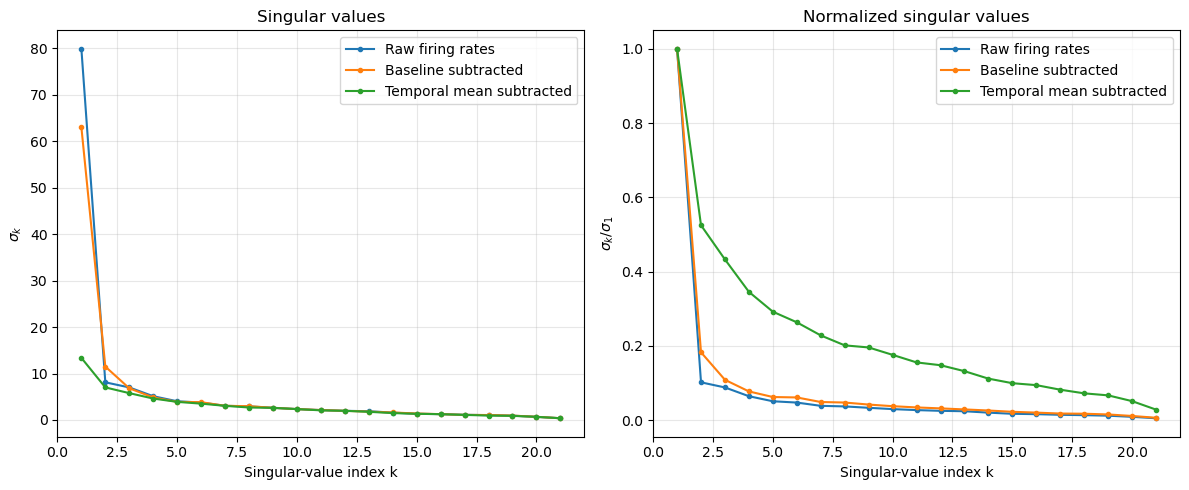

In [314]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

spectra = [
    (s_raw, "Raw firing rates"),
    (s_baseline, "Baseline subtracted"),
    (s_centered, "Temporal mean subtracted")
]

for s, label in spectra:
    k = np.arange(1, len(s) + 1)

    # Unnormalized singular values
    axes[0].plot(k, s, "o-", markersize=3, label=label)

    # Normalized singular values
    axes[1].plot(k, s / s[0], "o-", markersize=3, label=label)

axes[0].set_title("Singular values")
axes[0].set_ylabel(r"$\sigma_k$")

axes[1].set_title("Normalized singular values")
axes[1].set_ylabel(r"$\sigma_k / \sigma_1$")

for ax in axes:
    ax.set_xlabel("Singular-value index k")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

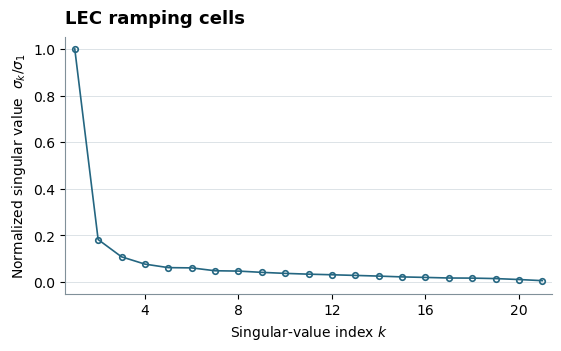

In [315]:
s_centered_normalized = s_centered / s_centered[0]
s_baseline_normalized = s_baseline / s_baseline[0]
s_raw_normalized = s_raw / s_raw[0]

normalized = s_baseline_normalized

n_show = s_centered.shape[0]
k = np.arange(1, n_show + 1)

fig, ax = plt.subplots(figsize=(5.5, 3.4), layout="constrained")

ax.plot(
    k, normalized[:n_show],
    color="#246681",
    linewidth=1.2,
    marker="o",
    markersize=4,
    markerfacecolor="none",
    markeredgecolor="#246681",
    markeredgewidth=1.2,
)

ax.set_title("LEC ramping cells", loc="left", fontsize=13,
             fontweight="bold", pad=10)
ax.set_xlabel(r"Singular-value index $k$")
ax.set_ylabel(r"Normalized singular value  $\sigma_k/\sigma_1$")
ax.set_ylim(-0.05, 1.05)
ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
ax.margins(x=0.02)

ax.set_axisbelow(True)
ax.grid(axis="y", color="#dce3e7", linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#809099")

fig.savefig(f"tsao_svd_{n_show}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
singular_value